# Chapter 14: Comparing Many Groups

Companion notebook for *Master Exploratory Data Analysis: A Hands-On Beginner's Guide with Python, Statistics & A/B Testing*.

Run the cells from top to bottom (**Kernel → Restart Kernel and Run All Cells**). The data files are in the same folder as this notebook.

## 14.1 Why Not Just Run Six t-Tests?

In [1]:
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd
from statsmodels.stats.multitest import multipletests

plt.style.use('book.mplstyle')

orders = pd.read_csv('orders.csv', parse_dates=['order_date'])
customers = pd.read_csv('customers.csv', parse_dates=['signup_date'])
cancellations = pd.read_csv('cancellations.csv',
                            parse_dates=['cancel_date'])


def p_text(p):
    return 'p < 0.001' if p < 0.001 else f'p = {p:.3f}'


regions = ['Northeast', 'Midwest', 'South', 'West']
orders_region = orders.merge(customers[['customer_id', 'region']],
                             on='customer_id', validate='many_to_one')
add_ons = orders_region[orders_region['order_type'] == 'Add-on']
print(f'{len(orders_region):,} orders, {len(add_ons):,} add-ons')

28,772 orders, 4,520 add-ons


In [2]:
add_on_summary = add_ons.groupby('region')['amount'].agg(
    ['count', 'mean', 'median', 'std'])
add_on_summary.round(2).loc[regions]

,count,mean,median,std
region,,,,
Northeast,1149,24.90,18.51,37.23
Midwest,854,24.41,17.97,38.09
South,1182,25.39,18.19,39.29
West,1335,27.88,21.83,24.07


In [3]:
pairs = list(combinations(regions, 2))
for a, b in pairs:
    print(a, 'vs', b)

Northeast vs Midwest
Northeast vs South
Northeast vs West
Midwest vs South
Midwest vs West
South vs West


### The false-alarm math

In [4]:
for k in [1, 6, 20, 190]:
    print(f'Tests: {k:>3}   chance of a false alarm: '
          f'{1 - 0.95 ** k:.0%}')

Tests:   1   chance of a false alarm: 5%
Tests:   6   chance of a false alarm: 26%
Tests:  20   chance of a false alarm: 64%
Tests: 190   chance of a false alarm: 100%


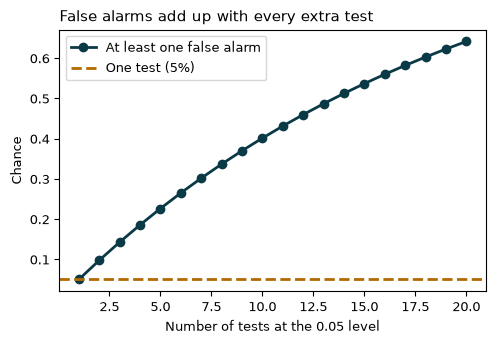

In [5]:
k = np.arange(1, 21)
fig, ax = plt.subplots()
ax.plot(k, 1 - 0.95 ** k, marker='o', color='#0b3a47',
        label='At least one false alarm')
ax.axhline(0.05, color='#b26a00', linestyle='--',
           label='One test (5%)')
ax.set_title('False alarms add up with every extra test')
ax.set_xlabel('Number of tests at the 0.05 level')
ax.set_ylabel('Chance')
ax.legend()
plt.show()

### Seeing it with shuffled labels

In [6]:
rng = np.random.default_rng(42)
amounts = add_ons['amount'].to_numpy()
labels = add_ons['region'].to_numpy()

shuffle_p = []
for _ in range(1000):
    shuffled = rng.permutation(labels)
    p_values = []
    for a, b in pairs:
        test = stats.ttest_ind(amounts[shuffled == a],
                               amounts[shuffled == b],
                               equal_var=False)
        p_values.append(test.pvalue)
    shuffle_p.append(p_values)
shuffle_p = np.array(shuffle_p)

any_alarm = (shuffle_p < 0.05).any(axis=1)
print(f'Shuffles with at least one "significant" pair: '
      f'{any_alarm.mean():.1%}')

Shuffles with at least one "significant" pair: 21.3%


## 14.2 One Test for All the Groups

In [7]:
orders_region.groupby('region')['delivery_days'].agg(
    ['count', 'mean', 'std']).round(2).loc[regions]

,count,mean,std
region,,,
Northeast,7368,2.79,1.37
Midwest,5289,3.07,1.45
South,7834,3.31,1.52
West,8281,3.88,1.69


### `stats.f_oneway()`

In [8]:
def split_by_region(df, column):
    groups = {}
    for region in regions:
        groups[region] = df.loc[df['region'] == region, column]
    return groups


days = split_by_region(orders_region, 'delivery_days')
print(days['West'].mean().round(2))

3.88


In [9]:
delivery_anova = stats.f_oneway(*days.values())
print(f'statistic: {delivery_anova.statistic}')
print(f'pvalue: {delivery_anova.pvalue}')

statistic: 719.8010189029974
pvalue: 0.0


In [10]:
print(p_text(delivery_anova.pvalue))

p < 0.001


### How much does the grouping explain?

In [11]:
def eta_squared(values, groups):
    group_means = values.groupby(groups).transform('mean')
    between = ((group_means - values.mean()) ** 2).sum()
    total = ((values - values.mean()) ** 2).sum()
    return between / total


delivery_eta = eta_squared(orders_region['delivery_days'],
                           orders_region['region'])
print(f'eta-squared: {delivery_eta:.3f}')

eta-squared: 0.070


## 14.3 Checking for Equal Spread

### `stats.levene()`

In [12]:
print(p_text(stats.levene(*days.values()).pvalue))

p < 0.001


### Welch's ANOVA with `equal_var=False`

In [13]:
welch_days = stats.f_oneway(*days.values(), equal_var=False)
print(p_text(welch_days.pvalue))

p < 0.001


## 14.4 Skewed Groups: Add-On Amounts by Region

In [14]:
gifts = add_ons['items'] >= 10
gifts.groupby(add_ons['region']).sum().loc[regions]

region
Northeast    7
Midwest      5
South        7
West         5
Name: items, dtype: int64

### The revenue question: averages

In [15]:
amounts_by_region = split_by_region(add_ons, 'amount')
print(p_text(stats.levene(*amounts_by_region.values()).pvalue))

p = 0.981


In [16]:
region_medians = add_ons.groupby('region')['amount'].transform(
    'median')
distance = (add_ons['amount'] - region_medians).abs()
distance.groupby(add_ons['region']).mean().round(2).loc[regions]

region
Northeast    12.05
Midwest      11.94
South        12.39
West         12.44
Name: amount, dtype: float64

In [17]:
amount_anova = stats.f_oneway(*amounts_by_region.values())
amount_eta = eta_squared(add_ons['amount'], add_ons['region'])
print(f'F = {amount_anova.statistic:.2f}, '
      f'{p_text(amount_anova.pvalue)}')
print(f'eta-squared: {amount_eta:.4f}')

F = 2.36, p = 0.069
eta-squared: 0.0016


In [18]:
welch_amounts = stats.f_oneway(*amounts_by_region.values(),
                               equal_var=False)
print(p_text(welch_amounts.pvalue))

p = 0.019


### The typical-order question: ranks

#### `stats.kruskal()`

In [19]:
amount_kw = stats.kruskal(*amounts_by_region.values())
print(f'statistic: {amount_kw.statistic}')
print(f'pvalue: {amount_kw.pvalue}')

statistic: 99.99893141465044
pvalue: 1.5549818824243833e-21


In [20]:
print(p_text(amount_kw.pvalue))

p < 0.001


In [21]:
ranks = add_ons['amount'].rank()
ranks.groupby(add_ons['region']).mean().round(0).loc[regions]

region
Northeast    2145.0
Midwest      2090.0
South        2160.0
West         2558.0
Name: amount, dtype: float64

### Cross-checks for the typical order

In [22]:
add_ons['log_amount'] = np.log1p(add_ons['amount'])
logs_by_region = split_by_region(add_ons, 'log_amount')
regular = add_ons[~gifts]
regular_by_region = split_by_region(regular, 'amount')

print('Spread, log amounts:     ',
      p_text(stats.levene(*logs_by_region.values()).pvalue))
print('ANOVA, log amounts:      ',
      p_text(stats.f_oneway(*logs_by_region.values()).pvalue))
print('Spread, no gift orders:  ',
      p_text(stats.levene(*regular_by_region.values()).pvalue))
print('Welch, no gift orders:   ',
      p_text(stats.f_oneway(*regular_by_region.values(),
                            equal_var=False).pvalue))

Spread, log amounts:      p = 0.863
ANOVA, log amounts:       p < 0.001
Spread, no gift orders:   p < 0.001
Welch, no gift orders:    p < 0.001


In [23]:
log_eta = eta_squared(add_ons['log_amount'], add_ons['region'])
print(f'eta-squared, log amounts: {log_eta:.3f}')

eta-squared, log amounts: 0.019


## 14.5 Which Groups Differ?

### `pairwise_tukeyhsd()`

In [24]:
tukey = pairwise_tukeyhsd(add_ons['log_amount'], add_ons['region'])
tukey_table = tukey.summary_frame()
tukey_table['p'] = tukey_table['p-adj'].map(p_text)
tukey_table[['group_t', 'group_c', 'meandiff',
             'lower', 'upper', 'p']].round(3)

,group_t,group_c,meandiff,lower,upper,p
0,Northeast,Midwest,0.020,-0.044,0.085,p = 0.854
1,South,Midwest,0.032,-0.033,0.096,p = 0.586
2,West,Midwest,0.186,0.124,0.249,p < 0.001
3,South,Northeast,0.011,-0.048,0.071,p = 0.960
4,West,Northeast,0.166,0.109,0.223,p < 0.001
5,West,South,0.155,0.098,0.212,p < 0.001


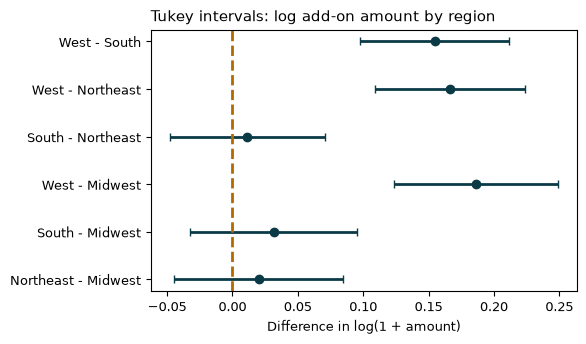

In [25]:
pair_names = tukey_table['group_t'] + ' - ' + tukey_table['group_c']
fig, ax = plt.subplots()
ax.errorbar(tukey_table['meandiff'], pair_names,
            xerr=[tukey_table['meandiff'] - tukey_table['lower'],
                  tukey_table['upper'] - tukey_table['meandiff']],
            fmt='o', color='#0b3a47', capsize=3)
ax.axvline(0, color='#b26a00', linestyle='--')
ax.set_title('Tukey intervals: log add-on amount by region')
ax.set_xlabel('Difference in log(1 + amount)')
plt.show()

In [26]:
west_rows = tukey_table[tukey_table['group_t'] == 'West']
pct_higher = np.expm1(west_rows['meandiff'])
pd.Series(pct_higher.to_numpy(), index=west_rows['group_c']).round(3)

group_c
Midwest      0.205
Northeast    0.181
South        0.167
dtype: float64

## 14.6 Adjusting Many p-Values

### `multipletests()`

In [27]:
campaign_p = [0.004, 0.011, 0.019, 0.032, 0.30]
multipletests(campaign_p, method='bonferroni')

(array([ True, False, False, False, False]),
 array([0.02 , 0.055, 0.095, 0.16 , 1.   ]),
 np.float64(0.010206218313011495),
 0.01)

In [28]:
for method in ['bonferroni', 'holm', 'fdr_bh']:
    reject, p_adjusted, _, _ = multipletests(campaign_p,
                                             method=method)
    print(f'{method:>10}: {p_adjusted.round(3)}  '
          f'significant: {reject.sum()}')

bonferroni: [0.02  0.055 0.095 0.16  1.   ]  significant: 1
      holm: [0.02  0.044 0.057 0.064 0.3  ]  significant: 2
    fdr_bh: [0.02  0.027 0.032 0.04  0.3  ]  significant: 4


### Back to the shuffles

In [29]:
holm_alarm = []
for p_values in shuffle_p:
    reject, _, _, _ = multipletests(p_values, method='holm')
    holm_alarm.append(reject.any())
print(f'Without adjusting: {any_alarm.mean():.1%}')
print(f'With Holm:         {np.mean(holm_alarm):.1%}')

Without adjusting: 21.3%
With Holm:         3.0%


### Every pair of regions for delivery times

In [30]:
rows = []
for a, b in pairs:
    test = stats.ttest_ind(days[b], days[a], equal_var=False)
    rows.append({'pair': f'{b} - {a}',
                 'gap_days': days[b].mean() - days[a].mean(),
                 'p_raw': test.pvalue})
delivery_pairs = pd.DataFrame(rows)

_, p_holm, _, _ = multipletests(delivery_pairs['p_raw'],
                                method='holm')
delivery_pairs['p_holm'] = [p_text(p) for p in p_holm]
delivery_pairs[['pair', 'gap_days', 'p_holm']].round(2)

,pair,gap_days,p_holm
0,Midwest - Northeast,0.29,p < 0.001
1,South - Northeast,0.53,p < 0.001
2,West - Northeast,1.09,p < 0.001
3,South - Midwest,0.24,p < 0.001
4,West - Midwest,0.81,p < 0.001
5,West - South,0.57,p < 0.001


## 14.7 Rates Are Different: Cancellations by Region

In [31]:
customers['cancelled'] = customers['customer_id'].isin(
    cancellations['customer_id'])
region_cancel = pd.crosstab(customers['region'],
                            customers['cancelled']).loc[regions]
region_cancel

cancelled,False,True
region,,
Northeast,452,589
Midwest,343,390
South,520,635
West,526,755


In [32]:
cancel_test = stats.chi2_contingency(region_cancel)
print(p_text(cancel_test.pvalue))
print(f"Cramér's V: "
      f'{stats.contingency.association(region_cancel):.2f}')
print(customers.groupby('region')['cancelled'].mean()
      .round(3).loc[regions])

p = 0.062
Cramér's V: 0.04
region
Northeast    0.566
Midwest      0.532
South        0.550
West         0.589
Name: cancelled, dtype: float64
